In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

In [2]:
with open("MNISTsmall.p", "rb") as data_file:
    D = pickle.load(data_file)

In [3]:
D

{'data': array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], dtype=uint8),
 'target': array([0, 0, 0, ..., 9, 9, 9], dtype=uint8),
 'DESCR': 'A subset of the MNIST database of handwritten digits.\nThe original database was developed by Yann LeCun, Corinna Cortes, and Chris Burges. \nFor more information check: http://http://yann.lecun.com/exdb/mnist/.\n\nThe MNISTsmall dataset is composed  of 15000 images of 28x28 pixels consisting of handwritten digits 0 to 9.\nThe first 10000 correspond the the training set and the last 5000 to the test data (also accessible via "foldTrain" variable).\nThe data is packed in a dictionary-type object (actually a utils.Bunch object of sklearn):\ndata   --> dxN where N=15000 (the number of examples) and d=784=28x28 (data dimension)\ntarget --> N   labels from 0 to 9 (examples\' classes)\n',
 'targe

In [4]:
D.keys()

dict_keys(['data', 'target', 'DESCR', 'target_names', 'foldTrain'])

In [5]:
X = D['data']
y = D['target']

print("X shape:", X.shape)
print("Y shape:", y.shape)

print(np.unique(y))

X shape: (784, 15000)
Y shape: (15000,)
[0 1 2 3 4 5 6 7 8 9]


# 1.

#### Considere os 396 primeiros exemplos do conjunto de treino do digito “5”

# a. 
#### O numero de pixeis com valor igual a zero para todos os exemplos deste conjunto 

In [6]:
# Filtrar os índices dos primeiros 396 exemplos do dígito "5"
indices_five = np.where(y == 5)[0][:396]

# Selecionar as colunas correspondentes ao dígito "5"
X_five = X[:, indices_five]

# Determinar os pixels com valor zero em todos os 396 exemplos
pixels_zero_all = np.all(X_five == 0, axis=1)

# Contar o número de pixels que são zero em todos os exemplos
num_pixels_zero_all = np.sum(pixels_zero_all)

print(f"Resposta: {num_pixels_zero_all}")

Resposta: 277


# b. 

#### O numero de valores proprios superiores a 10^−10 da matriz de covariancia dos dados é:

In [7]:
# Calcular a matriz de covariância
cov_matrix = np.cov(X_five)

# Calcular os valores próprios da matriz de covariância
eigenvalues, _ = np.linalg.eigh(cov_matrix) 

# Filtrar os valores próprios maiores que 10^(-10)
eigenvalues_significant = eigenvalues[eigenvalues > 1e-10]

# Contar o número de valores próprios que atendem ao critério
num_eigenvalues_significant = len(eigenvalues_significant)

print(f"Resposta: {num_eigenvalues_significant}")


Resposta: 395


# c.

#### Pretende-se visualizar os digitos deste conjunto e os vetores prorpios da matriz de covariancia dos dados

##### i. A figura de cima ́e a imagem invertida do 221 digito do conjunto.
##### ii. A figura de baixo e a imagem (ou a imagem invertida) do 15 vetor proprio da matriz de covariancia dos dados.

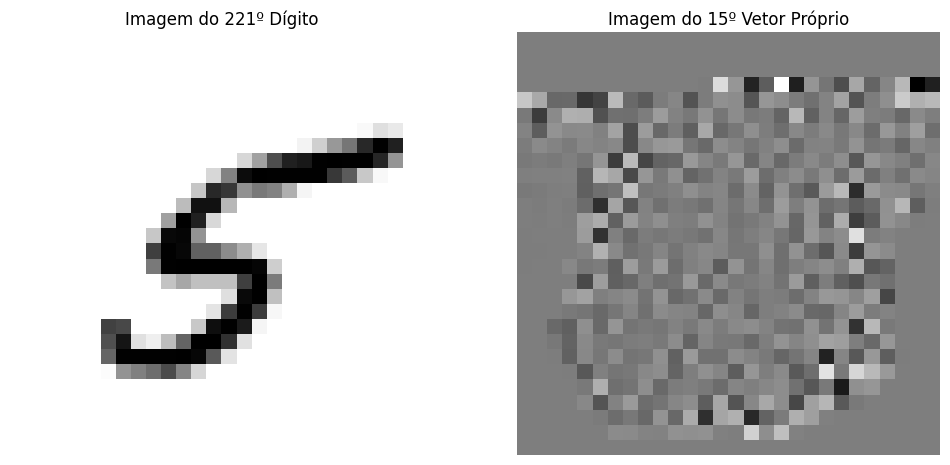

In [8]:
# Visualizar o 221º dígito do conjunto (lembrando que a indexação começa do 0)
digit_index = 220
digit_image = X_five[:, digit_index].reshape(28, 28)

# Calcular a matriz de covariância e obter os vetores próprios
cov_matrix = np.cov(X_five)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Visualizar o 15º vetor próprio
eigenvector_index = 14  
eigenvector_image = eigenvectors[:, eigenvector_index].reshape(28, 28)

plt.figure(figsize=(12, 6))

# Imagem do 221º dígito
plt.subplot(1, 2, 1)
plt.title("Imagem do 221º Dígito")
plt.imshow(digit_image, cmap='binary')
plt.axis('off')

# Imagem do 15º vetor próprio
plt.subplot(1, 2, 2)
plt.title("Imagem do 15º Vetor Próprio")
plt.imshow(eigenvector_image, cmap='gray')
plt.axis('off')

plt.show()


# d.

#### Para esta alinea, arredonde os valores pedidos a 2 casas decimais.
##### i. Existem 277 dimensoes dos dados que nao variam.
##### ii. O coeficiente de correlaçao entre a dimensao 381 e 382 é 0.85.


In [9]:
# Calcular a variância de cada dimensão (linha) da matriz de dados X
variances = np.var(X_five, axis=1)
num_dimensions_zero_variance = np.sum(variances < 1e-10)  # Consideramos uma tolerância de 1e-10 para variância zero

print(f"Resposta i: {num_dimensions_zero_variance}")

# Coeficiente de correlação entre a dimensão 381 e 382 (considerando que a indexação começa do 0)
dim_381 = X_five[380, :]  # Linha 381 (index 380)
dim_382 = X_five[381, :]  # Linha 382 (index 381)

correlation_381_382 = np.corrcoef(dim_381, dim_382)[0, 1]

print(f"Resposta ii: {round(correlation_381_382, 2)}")

Resposta i: 277
Resposta ii: 0.85


# e.

#### Para esta alinea, arredonde os valores pedidos a 0 casas decimais. Considere que os 136º, 222º, 273º e 378º digitos sao representados pelos vetores x1,x2,x3,e x4.

##### i. O produto interno entre os vetores x1 e x2  ́e 1 504 426.
##### ii. O produto interno entre os vetores x3 e x4  ́e 1 978 715.

In [10]:
# Índices dos vetores para os dígitos 136º, 222º, 273º e 378º
indices = [135, 221, 272, 377] 

# Obter os vetores correspondentes aos dígitos
x1 = X_five[:, indices[0]]*1.0
x2 = X_five[:, indices[1]]*1.0
x3 = X_five[:, indices[2]]*1.0
x4 = X_five[:, indices[3]]*1.0

# Calcular o produto interno entre x1 e x2, e x3 e x4
inner_product_x1_x2 = np.dot(x1, x2)
inner_product_x3_x4 = np.dot(x3, x4)

print(f"Resposta i: {np.round(inner_product_x1_x2, 0) == 1504426}")
print(f"Resposta ii: {np.round(inner_product_x3_x4, 0) == 1978715}")


Resposta i: False
Resposta ii: True


# f.
#### Considere que se estima a matriz de covariancia deste conjunto
##### i. A dimensão da matriz é 784 ×784.
##### ii. O determinante da matriz de convariancia é igual a 0. 

In [11]:
cov_matrix = np.cov(X_five)

print("Resposta i:", cov_matrix.shape)

# Calcular o determinante da matriz de covariância
det_cov_matrix = np.linalg.det(cov_matrix)
print("Resposta ii:", det_cov_matrix)

Resposta i: (784, 784)
Resposta ii: 0.0
